# Solve Inverse Problems - Simulations

Let's try out the inverse module on some simulations.


## 🧪 - Experiment setup
- `fwd`: Forward solution
- `ave`: Measurements
- `ncov`: Noise covariance
- `eig`: Eigenvectors and eigenvalues of the Connectome Lacplacian.

In [1]:
# imports
import mindmap as mm
import mne

# readers
dm = mm.io.TutoManager("../../config.yml")
sub = "intra48"

# data
fwd = dm.load(sub, "fwd")
ave = dm.load(sub, "ave", task="spk")
ncov = dm.load(sub, "cov", task="spk")
eig = dm.load(sub, "eig", desc="geom")

## 🧬 - Data Processing
Estimate regularization parameter

In [2]:
snr, _ = mm.analysis.eeg.estimate_evoked_snr(ave, baseline=(0,1), noise_cov=ncov)
snr = snr.max()
lambda2 = 1.0 / (snr**2)

print(f"Estimated SNR: {snr:.3f}")
print(f"Estimated lambda2: {lambda2:.3f}")

    Created an SSP operator (subspace dimension = 1)
Computing rank from covariance with rank=None
    Using tolerance 5.3e-12 (2.2e-16 eps * 208 dim * 1.2e+02  max singular value)
    Estimated rank (eeg): 207
    EEG: rank 207 computed from 208 data channels with 1 projector
    Setting small EEG eigenvalues to zero (without PCA)
    Created the whitener using a noise covariance matrix with rank 207 (1 small eigenvalues omitted)
Estimated SNR: 2.890
Estimated lambda2: 0.120


Apply inverse solver

In [3]:
# --------------------------------
# Methods implemented in MindMap
# ¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨
# --------------------------------

# mindmap's CSET
inv = mm.analysis.inverse.CSET(
    forward = fwd,
    noise_cov = ncov,
    depth = 0.8,
    eigenvectors = eig["vec"],
)

# cset = inv.solve(data, lambda2 = 0.1)


# mindmap's wCSET
inv = mm.analysis.inverse.wCSET(
    forward = fwd,
    noise_cov = ncov,
    depth = 0.5,
    eigenvectors = eig["vec"],
    eigenvalues = eig["val"],
    harm = 0.8,
)

wcset = inv.solve(ave, lambda2)

# mindmap's MCE
inv = mm.analysis.inverse.MCE(
    forward = fwd,
    noise_cov = ncov,
    depth = 0.8,
)

#mce = inv.solve(ave, lambda2 = 0.1)


# -----------------------------------
# Methods implemented in MNE-Python
# ¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨¨
# -----------------------------------


inv_mne = mne.minimum_norm.make_inverse_operator(
    info = ave.info,
    forward = fwd,
    noise_cov = ncov,
    fixed = True,
    depth = None,
)

# MNE-python's sLORETA
sloreta = mne.minimum_norm.apply_inverse(
    ave,
    inv_mne,
    lambda2,
    method = "sLORETA",
)

# MNE-python's dSPM
dspm = mne.minimum_norm.apply_inverse(
    ave,
    inv_mne,
    lambda2,
    method = "dSPM",
)

Computing inverse operator with 208 channels.
    208 out of 208 channels remain after picking
Selected 208 channels
    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]
Whitening the forward solution.
    Created an SSP operator (subspace dimension = 1)
Computing rank from covariance with rank=None
    Using tolerance 5.3e-12 (2.2e-16 eps * 208 dim * 1.2e+02  max singular value)
    Estimated rank (eeg): 207
    EEG: rank 207 computed from 208 data channels with 1 projector
    Setting small EEG eigenvalues to zero (without PCA)
Creating the source covariance matrix
Adjusting source covariance matrix.
Computing SVD of whitened and weighted lead field matrix.
    largest singular value = 11.2791
    scaling factor to adjust the trace = 4.96487e+22 (nchan = 208 nzero = 1)
Preparing the inverse operator for use...
    Scaled noise and source covariance from nave = 1 to nave = 265


## 📊 - Visualization

Measurements - timeseries

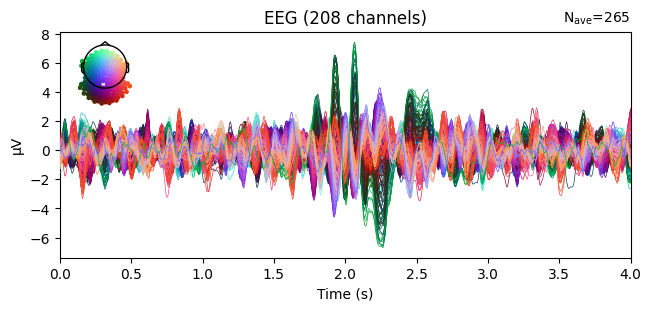

In [4]:
_ = ave.plot(xlim=(0, 4))

Measurements - topographies

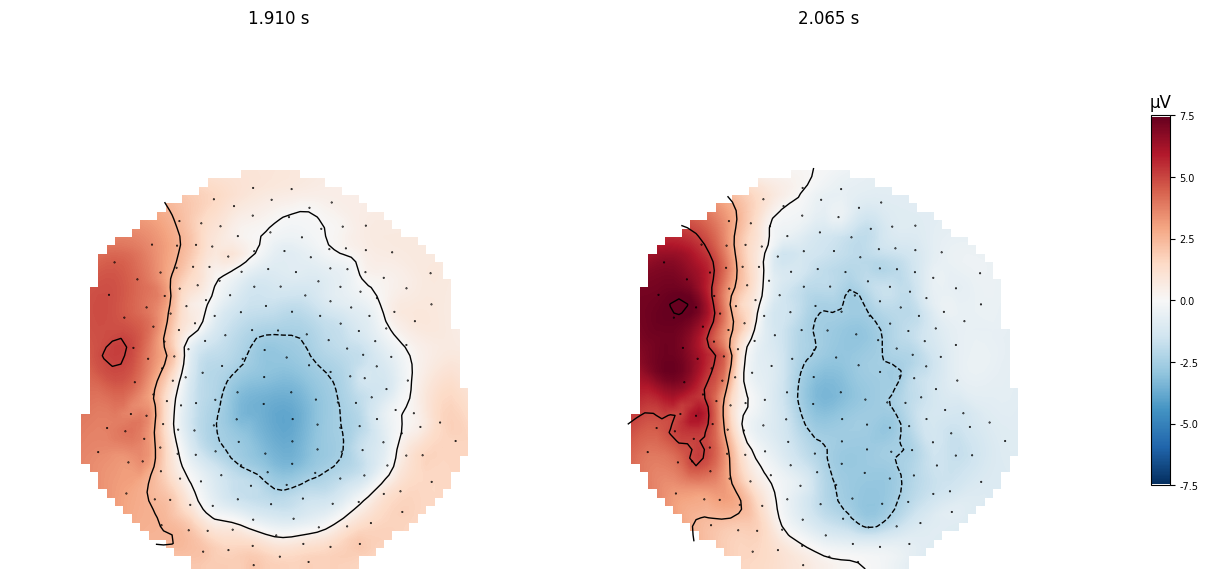

In [5]:
hrp = mm.analysis.eeg.get_rising_phase(ave, ratio=0.5)    # half rising phase
pp  = mm.analysis.eeg.get_rising_phase(ave, ratio=1)      # peak phase

_ = ave.plot_topomap(times=[hrp, pp], size=4, extrapolate="local", outlines=None)

Source reconstruction

In [6]:
func_params = {"normalize": "max", "absolute": True}
panels = [
    mm.viz.BrainPlot.from_source_space(
        fwd["src"], stc.data, states=stc.times, title=name,
        scalar_name="Source Activity", func_params=func_params,
    )
    for name, stc in [("wcset", wcset), ("sloreta", sloreta), ("dspm", dspm)]
]
mm.viz.Layout([panels]).show(slider_label="Time [s]", jupyter_backend="none")  # native window, not inline